In [1]:
import os
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.plugins.hparams.plugin_data_pb2 import HParamsPluginData

2025-03-16 18:39:10.700512: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-16 18:39:10.739681: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-16 18:39:10.739996: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-03-16 18:39:11.348450: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [128]:
# logdir = "tb_hparams_avg"  # Root directory containing all event logs

# def extract_hparams(event_path):
#     """Extracts hyperparameters from a single event file."""
#     hparams_list = []
    
#     for event in tf.compat.v1.train.summary_iterator(event_path):
#         for v in event.summary.value:
#             if v.tag == "_hparams_/session_start_info":
#                 hparams = {}
#                 plugin_data = HParamsPluginData.FromString(v.metadata.plugin_data.content)
#                 for k, v in plugin_data.session_start_info.hparams.items():
#                     if v.HasField("number_value"):
#                         hparams[k] = v.number_value
#                     elif v.HasField("string_value"):
#                         hparams[k] = v.string_value
#                 hparams_list.append(hparams)
    
#     return hparams_list

# # Find all event files
# event_files = []
# for root, _, files in os.walk(logdir):
#     for file in files:
#         if file.startswith("events"):
#             event_files.append(os.path.join(root, file))

# # Extract all hparams
# all_hparams = []
# for event_file in event_files:
#     all_hparams.extend(extract_hparams(event_file))

# # Create DataFrame
# df = pd.DataFrame(all_hparams)

In [26]:
import os
import tensorflow as tf
import pandas as pd
from tensorboard.plugins.hparams.plugin_data_pb2 import HParamsPluginData

logdir = "tb_hparams_avg"  # Root directory containing all event logs

def extract_hparams_from_event(event_path):
    """Extracts hyperparameters from a single event file."""
    hparams = {}
    
    for event in tf.compat.v1.train.summary_iterator(event_path):
        for v in event.summary.value:
            if v.tag == "_hparams_/session_start_info":
                plugin_data = HParamsPluginData.FromString(v.metadata.plugin_data.content)
                # Extract hyperparameters from session_start_info
                for k, param in plugin_data.session_start_info.hparams.items():
                    if param.HasField("number_value"):
                        hparams[k] = param.number_value
                    elif param.HasField("string_value"):
                        hparams[k] = param.string_value
                    else:
                        print(f"Unhandled parameter field: {k}")
    
    return hparams

def extract_metrics_from_event(event_path):
    """Extracts metrics from a single event file."""
    metrics = {}
    
    for event in tf.compat.v1.train.summary_iterator(event_path):
        for v in event.summary.value:
            if v.tag.startswith("mean_test_") or v.tag.startswith("std_test_") or \
               v.tag.startswith("mean_train_") or v.tag.startswith("std_train_"):
                metrics[v.tag] = v.simple_value
    
    return metrics

def process_event_files(event_files):
    """Process event files and return a list of dictionaries combining hparams and metrics."""
    all_data = []
    for event_file in event_files:
        # Try to extract hyperparameters
        hparams = extract_hparams_from_event(event_file)
        
        # Try to extract metrics
        metrics = extract_metrics_from_event(event_file)
        
        # Combine hparams and metrics if both are found
        if hparams or metrics:
            combined_data = {**hparams, **metrics}
            all_data.append(combined_data)
    
    return all_data

# Find all event files
event_files = []
for root, _, files in os.walk(logdir):
    for file in files:
        if file.startswith("events"):
            event_files.append(os.path.join(root, file))

# Process all event files
all_data = process_event_files(event_files)

# Create DataFrame
df = pd.DataFrame(all_data)

In [27]:
df = df.dropna(axis=1).drop(columns=['n_fold', 'test_size', 'train_size', 'input_size', 'mean_train_std_residual', 'std_train_std_residual', 'std_test_std_residual'])

In [40]:
df_lr = df[df['model'] == 'LinearRegression'].reset_index(drop=True)
df_lr = df_lr.loc[df_lr.groupby(['lowcut', 'highcut', 'autoregressive', 'include_present', 'past_history', 'forecast_horizon'])['mean_test_std_residual'].idxmin()]
df_mlp = df[df['model'] == 'MLPRegressor'].reset_index(drop=True)
df_mlp = df_mlp.loc[df_mlp.groupby(['lowcut', 'highcut', 'autoregressive', 'include_present', 'past_history', 'forecast_horizon'])['mean_test_std_residual'].idxmin()]

In [7]:
def plot_hparam(ax, hparam, df, colorby, logyscale=False):
    ax.scatter(df[hparam], df['mean_test_std_residual'], s=3, c=df[colorby])
    ax.set_ylabel('mean_test_std_residual')
    ax.set_xlabel(hparam)
    ax.grid(alpha=0.5)
    if logyscale:
        ax.set_yscale('log')

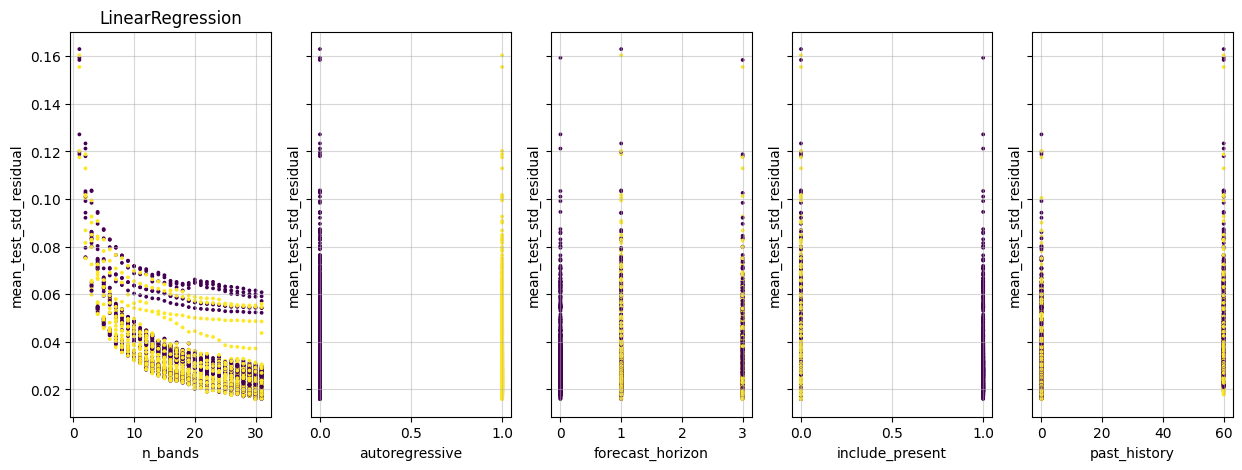

In [ ]:
df_lr_filtered = df_lr # [df_lr['autoregressive'] == 1]
fig, axs = plt.subplots(1, 5, figsize=(15, 5), sharey=True)

axs[0].set_title('LinearRegression')
plot_hparam(axs[0], 'n_bands', df_lr_filtered, colorby='autoregressive')
plot_hparam(axs[1], 'autoregressive', df_lr_filtered, colorby='autoregressive')
plot_hparam(axs[2], 'forecast_horizon', df_lr_filtered, colorby='autoregressive')
plot_hparam(axs[3], 'include_present', df_lr_filtered, colorby='autoregressive')
plot_hparam(axs[4], 'past_history', df_lr_filtered, colorby='autoregressive')

plt.show()

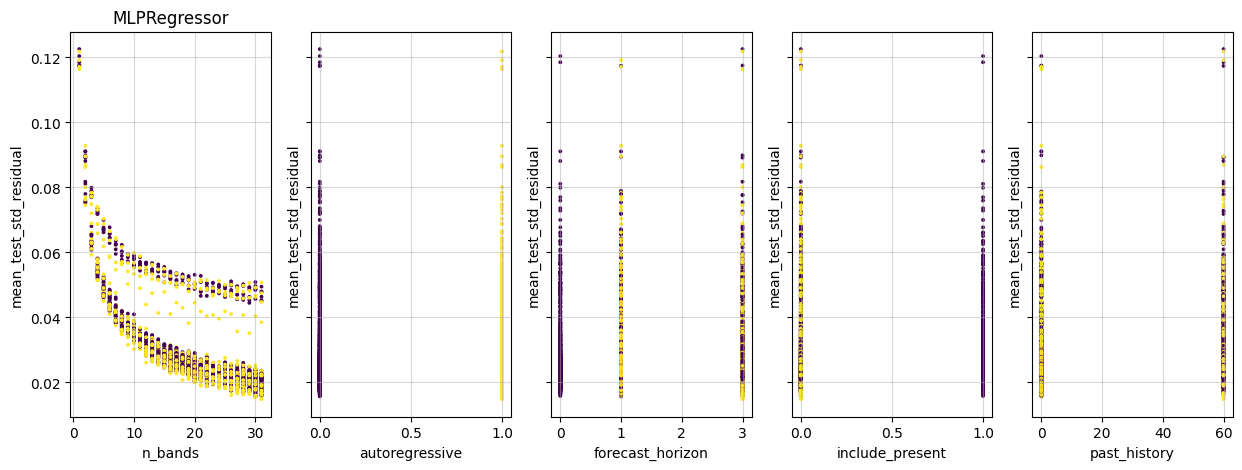

In [44]:
fig, axs = plt.subplots(1, 5, figsize=(15, 5), sharey=True)

axs[0].set_title('MLPRegressor')
plot_hparam(axs[0], 'n_bands', df_mlp, colorby='autoregressive')
plot_hparam(axs[1], 'autoregressive', df_mlp, colorby='autoregressive')
plot_hparam(axs[2], 'forecast_horizon', df_mlp, colorby='autoregressive')
plot_hparam(axs[3], 'include_present', df_mlp, colorby='autoregressive')
plot_hparam(axs[4], 'past_history', df_mlp, colorby='autoregressive')

plt.show()